# 02. RR-BLUP и его эквивалентность с GBLUP

Модель:

$$y = \mathbf{1}\mu + Z\beta + e, \qquad \beta_j \sim N(0, \sigma^2_\beta), \quad e \sim N(0, I\sigma^2_e)$$

Маркеров больше, чем линий (1279 против 599), так что обычный МНК тут не
работает — система недоопределена. Выход стандартный: считать эффекты
маркеров случайными с общей дисперсией σ²_β. Тогда все эффекты тянутся
к нулю одинаково, и задача решается.

Решение — смешанные уравнения Хендерсона:

$$(Z'Z + \lambda I)\,\hat\beta = Z'(y - \bar y), \qquad \lambda = \sigma^2_e / \sigma^2_\beta$$

По сути это ridge-регрессия, отсюда название — Ridge Regression BLUP.

Осталось откуда-то взять λ. Я оцениваю дисперсии через REML
(`preprocessing.reml_variance_components`) для эквивалентной
GBLUP-модели, а потом пересчитываю в маркерную шкалу:
σ²_β = σ²_g / c и λ = σ²_e / σ²_β, где c = 2Σp(1−p).

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# проект импортируется и из корня, и из папки notebooks/
for cand in [Path.cwd(), Path.cwd().parent]:
    if (cand / "gp_models" / "__init__.py").exists():
        sys.path.insert(0, str(cand))
        PROJECT = cand
        break

import gp_models as gpm
from gp_models import data, preprocessing as pp

matplotlib.rcParams["font.family"] = ["Liberation Sans", "Arimo", "DejaVu Sans"]
matplotlib.rcParams["svg.fonttype"] = "none"
FIGDIR = PROJECT / "figures"
FIGDIR.mkdir(exist_ok=True)
%matplotlib inline


REML: sigma2_g=1.206, sigma2_e=0.541, h2=0.690
sigma2_beta = 0.00283 -> lambda = 191.2
mu=0.000; |beta|: max=0.0691, mean=0.01447


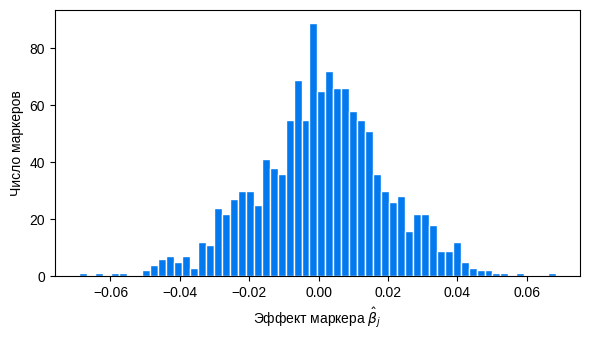

In [2]:
w = data.load_wheat()
X, Y = w["X"], w["Y"]
y = Y[:, 0]                      # среда 1
Z, p, c = pp.center_markers(X)

from gp_models import rrblup
lam, vc = rrblup.lam_from_reml(y, X)
print(f"REML: sigma2_g={vc['sigma2_g']:.3f}, sigma2_e={vc['sigma2_e']:.3f}, "
      f"h2={vc['h2']:.3f}")
print(f"sigma2_beta = {vc['sigma2_g']/c:.5f} -> lambda = {lam:.1f}")

fit = rrblup.rrblup_fit(y, Z, lam)
print(f"mu={fit['mu']:.3f}; |beta|: max={np.abs(fit['beta']).max():.4f}, "
      f"mean={np.abs(fit['beta']).mean():.5f}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(fit["beta"], bins=60, color="#0279EE", edgecolor="white")
ax.set_xlabel("Эффект маркера $\\hat\\beta_j$"); ax.set_ylabel("Число маркеров")
plt.tight_layout(); plt.show()

## Проверка: RR-BLUP и GBLUP — это одно и то же

Ту же модель можно записать двумя способами:

- через маркеры: β ~ N(0, I σ²_β), прогноз g = Zβ;
- через линии (GBLUP): g ~ N(0, G σ²_g), где G = ZZ′/c и σ²_g = c·σ²_β.

По Хендерсону решения совпадают: ĝ = Zβ̂. Звучит абстрактно, поэтому
проверяю численно. GBLUP решается через V = σ²_g·G + σ²_e·I:

$$\hat g = \sigma^2_g\, G V^{-1}(y - \mathbf{1}\hat\mu), \qquad
\hat\mu = (\mathbf{1}'V^{-1}\mathbf{1})^{-1}\mathbf{1}'V^{-1}y$$

max |GEBV_RRBLUP - GEBV_GBLUP| = 7.77e-15  (относительно sd(GEBV): 1.4e-14)


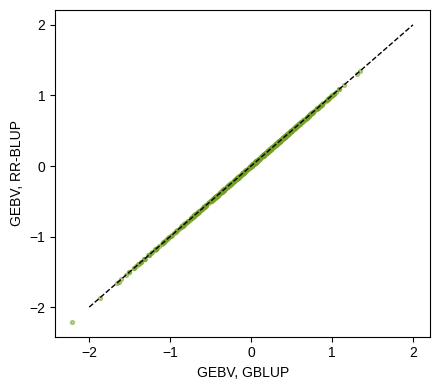

In [3]:
from gp_models import gblup
G = Z @ Z.T / c
fit_gb = gblup.gblup_fit(y, G, vc["sigma2_g"], vc["sigma2_e"])

d = np.abs(fit["gebv"] - fit_gb["gebv"])
print(f"max |GEBV_RRBLUP - GEBV_GBLUP| = {d.max():.2e}  "
      f"(относительно sd(GEBV): {d.max()/fit_gb['gebv'].std():.1e})")

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.scatter(fit_gb["gebv"], fit["gebv"], s=8, alpha=0.5, color="#75A025")
ax.plot([-2, 2], [-2, 2], "k--", lw=1)
ax.set_xlabel("GEBV, GBLUP"); ax.set_ylabel("GEBV, RR-BLUP")
plt.tight_layout(); plt.show()

## Контроль против sklearn

Ridge из sklearn решает (Z′Z + αI)β = Z′y — ровно наша система при α = λ.
Если мой код правильный, коэффициенты должны совпасть до погрешности
солвера.

In [4]:
from sklearn.linear_model import Ridge
r = Ridge(alpha=lam, fit_intercept=True).fit(Z, y)
print(f"corr(beta_Ridge, beta_RRBLUP) = {np.corrcoef(r.coef_, fit['beta'])[0,1]:.8f}")
print(f"max |d_beta| = {np.abs(r.coef_ - fit['beta']).max():.2e}")

corr(beta_Ridge, beta_RRBLUP) = 1.00000000
max |d_beta| = 1.11e-15


## Что тут важно

- λ = σ²_e/σ²_β регулирует стягивание: чем больше λ, тем сильнее эффекты
  прижаты к нулю. Тут λ ≈ 191 — маркеров много, дисперсия на один маркер
  крошечная.
- h² = 0.69 для урожайности в среде 1 — высокая (правда, Y — это средние
  по повторениям, так что часть шума уже вычтена).
- RR-BLUP и GBLUP — одна модель в двух записях. Что считать — вопрос
  удобства: если маркеров меньше, чем линий, дешевле маркерная форма,
  если наоборот — через G.
- Дальше (03) та же модель, но по-байесовски: дисперсии не фиксируем, а
  сэмплируем (BRR). Это заготовка под BayesA (04).